# Análisis del comportamiento de una aplicación bajo diferentes escenarios de despliegue

**Proyecto final · Principios y prácticas de Desarrollo de Software Orientado a Objetos**
**Autores:** Angela Lozano (`alalo10`) y Juan José Rangel García
**Repositorio:** https://github.com/alalo10/Proyecto_kubernetes_k8s

---

## 1. Introducción y objetivos

Este notebook documenta y analiza el despliegue de **una misma aplicación** (gestión de citas médicas) en distintos escenarios:

| Escenario | Descripción |
|---|---|
| **Docker Compose** | API + PostgreSQL en una sola máquina (distinta a la que genera la carga). |
| **Kubernetes 1 nodo** | K3s con un nodo, variando la API a 1, 2 y 3 réplicas. |
| **Kubernetes 2 nodos** | K3s con dos nodos, 1, 2 y 3 réplicas. |
| **Kubernetes 3 nodos** | K3s con tres nodos, 1, 2 y 3 réplicas. |

En cada escenario se genera carga con **Apache JMeter** y se miden el **tiempo medio de respuesta** y el **throughput** (peticiones por segundo). El objetivo es entender cómo el entorno de despliegue (número de réplicas y de nodos) afecta a la aplicación y qué podemos concluir sobre su **escalabilidad horizontal** y la eficiencia en el uso de recursos.

**Cómo está organizado el notebook**

1. Introducción · 2. Aplicación · 3. Configuración de despliegue · 4. Monitorización · 5. Metodología de carga · 6. Datos · 7. Gráficas · 8. Análisis comparativo · 9. Conclusiones · 10. Recomendaciones · 11. Cómo reproducir

## 2. Descripción de la aplicación

**API de Citas Médicas** (Python + FastAPI + PostgreSQL). Es un backend con lógica de negocio, accesible por API REST y con persistencia en base de datos relacional, que es lo que exige el proyecto.

**Entidades** (cada una es una clase de SQLAlchemy, es decir, una tabla):

- `Paciente`: nombre, documento (único), teléfono, correo.
- `Medico`: nombre, especialidad.
- `Cita`: paciente, médico, fecha y hora, motivo y estado (`programada`, `cancelada`, `completada`).

**Endpoints principales**

| Método | Ruta | Función |
|---|---|---|
| GET | `/citas` | Lista con filtros (médico, paciente, estado, rango de fechas) y paginación (`skip`, `limit`). |
| GET | `/citas/{id}` | Consulta una cita. |
| POST | `/citas` | Crea una cita (valida que existan paciente y médico). |
| PUT / DELETE | `/citas/{id}` | Actualiza o elimina. |
| GET/POST/PUT/DELETE | `/pacientes`, `/medicos` | CRUD equivalente. |
| GET | `/health` | Comprobación de salud (hace un `SELECT 1`); la usará Kubernetes. |

**Lógica de negocio relevante**

- Un médico **no puede tener dos citas en la misma fecha y hora**. Se valida con una consulta previa (mensaje claro, HTTP 409) y, como respaldo ante peticiones simultáneas, con una restricción `UNIQUE (medico_id, fecha_hora)` en la base de datos.
- Los listados son siempre paginados (máximo 500 filas); así una petición `GET` no devuelve las 20.000 citas de golpe y las mediciones no se distorsionan.

**Decisiones de diseño con efecto en el rendimiento**

- Índices en las columnas por las que se filtra (`medico_id`, `paciente_id`, `fecha_hora`, `estado`).
- Pool de conexiones a PostgreSQL (`pool_size=10`, `max_overflow=20`) por proceso.
- La API corre con **un único proceso de uvicorn** por contenedor. Cada réplica aprovecha, en la práctica, aproximadamente un núcleo de CPU. Esto es relevante para interpretar el efecto de añadir réplicas.
- La URL de la base de datos se lee de la variable de entorno `DATABASE_URL`, lo que permite usar **exactamente la misma imagen** (`citas-api:1.0`) en Docker Compose y en Kubernetes.

**Datos de prueba (más de 10.000 registros, requisito del proyecto):** el script `app/scripts/seed.py` carga **50 médicos, 5.000 pacientes y 20.000 citas = 25.050 registros**, con semilla fija para que los datos sean idénticos en todas las máquinas.

In [1]:
import os, re, glob, subprocess

REPO_URL = "https://github.com/alalo10/Proyecto_kubernetes_k8s.git"
REPO_DIR = "Proyecto_kubernetes_k8s"

if os.getenv("DATOS_DIR") is None:
    # Uso normal (Colab o local): se clona el repositorio y se leen los resultados desde él
    if os.path.isdir(REPO_DIR):
        subprocess.run(["git", "-C", REPO_DIR, "pull", "--quiet"], check=False)
    else:
        subprocess.run(["git", "clone", "--depth", "1", "--quiet", REPO_URL], check=True)
    RAIZ = REPO_DIR
    DATOS_DIR = os.path.join(RAIZ, "jmeter", "resultados")
else:
    # Modo de pruebas del propio notebook (ruta indicada por variable de entorno)
    RAIZ = os.getenv("RAIZ_REPO", ".")
    DATOS_DIR = os.environ["DATOS_DIR"]

print("Raíz del repositorio :", RAIZ)
print("Carpeta de resultados:", DATOS_DIR)
print("Archivos .jtl encontrados:", len(glob.glob(os.path.join(DATOS_DIR, "*.jtl"))))

Raíz del repositorio : ..
Carpeta de resultados: ../jmeter/resultados
Archivos .jtl encontrados: 30


In [2]:
def mostrar(ruta_relativa):
    # Imprime un archivo del repositorio (si existe) para documentar la configuración
    p = os.path.join(RAIZ, ruta_relativa)
    print("=" * 70)
    print("#", ruta_relativa)
    print("=" * 70)
    if os.path.exists(p):
        print(open(p, encoding="utf-8").read())
    else:
        print("(todavía no está en el repositorio)")

for f in ["app/models.py", "app/routers/citas.py"]:
    mostrar(f)

# app/models.py
import enum
from datetime import datetime

from sqlalchemy import (
    Column,
    DateTime,
    Enum,
    ForeignKey,
    Integer,
    String,
    UniqueConstraint,
)
from sqlalchemy.orm import relationship

from database import Base


class EstadoCita(str, enum.Enum):
    """Estados posibles de una cita."""
    programada = "programada"
    cancelada = "cancelada"
    completada = "completada"


class Paciente(Base):
    __tablename__ = "pacientes"

    id = Column(Integer, primary_key=True, index=True)
    nombre = Column(String(100), nullable=False)
    documento = Column(String(20), unique=True, nullable=False, index=True)
    telefono = Column(String(30))
    correo = Column(String(100))

    citas = relationship("Cita", back_populates="paciente")


class Medico(Base):
    __tablename__ = "medicos"

    id = Column(Integer, primary_key=True, index=True)
    nombre = Column(String(100), nullable=False)
    especialidad = Column(String(60), nullable=False, index=Tr

## 3. Configuración de despliegue por escenario

### 3.1 Infraestructura utilizada

| Rol | Máquina | Recursos |
|---|---|---|
| Servidor de la app en la Fase 1 y **control plane** de K3s | Portátil de Angela (Zorin OS) | 16 GB de RAM |
| Nodo 2 del clúster | VM `agente1` (Ubuntu), proporcionada por el profesor | 1 CPU, 3,8 GB de RAM |
| Nodo 3 del clúster | VM `GP19` (Ubuntu), proporcionada por el profesor | 1 CPU, 3,8 GB de RAM |
| **Generador de carga (JMeter)** — siempre | Portátil de Rangel (Windows) | 24 GB de RAM · JMeter 5.6.3 · Java 26 |

Los clústeres se arman así: **1 nodo** = portátil Zorin; **2 nodos** = Zorin + `agente1`; **3 nodos** = Zorin + `agente1` + `GP19`.

> **Importante para interpretar los resultados:** los nodos **no son homogéneos** (un portátil frente a dos VMs de 1 CPU) y las VMs son compartidas con contenedores de otras prácticas del curso. Además, todo el tráfico pasa por una red Wi-Fi/institucional con latencia variable (en los pings vimos desde ~3 ms hasta más de 100 ms). Estos factores se discuten en las conclusiones.

### 3.2 Fase 1 · Docker Compose

`docker/docker-compose.yml` levanta dos servicios: `db` (PostgreSQL 16, con *healthcheck* y volumen persistente) y `api` (nuestra imagen), que espera a que la base esté sana. Solo el puerto 8000 de la API se expone; la base de datos queda interna.

In [3]:
for f in ["app/Dockerfile", "docker/docker-compose.yml"]:
    mostrar(f)

# app/Dockerfile
FROM python:3.12-slim

WORKDIR /app

# Primero solo las dependencias: así Docker reutiliza esta capa
# si el código cambia pero requirements.txt no.
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

COPY . .

EXPOSE 8000

CMD ["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"]

# docker/docker-compose.yml
services:
  db:
    image: postgres:16
    container_name: citas-db
    environment:
      POSTGRES_USER: citas_user
      POSTGRES_PASSWORD: citas_pass
      POSTGRES_DB: citas_db
    volumes:
      - pgdata:/var/lib/postgresql/data
    healthcheck:
      test: ["CMD-SHELL", "pg_isready -U citas_user -d citas_db"]
      interval: 5s
      timeout: 5s
      retries: 10
    restart: unless-stopped

  api:
    build: ../app
    image: citas-api:1.0
    container_name: citas-api
    environment:
      DATABASE_URL: postgresql://citas_user:citas_pass@db:5432/citas_db
    depends_on:
      db:
        condition: service_healthy
    port

### 3.3 Fases 2, 3 y 4 · Kubernetes (K3s) con 1, 2 y 3 nodos

Se usa **K3s** (Kubernetes ligero) con el control plane en el portátil Zorin y las VMs como *workers*. En cada tamaño de clúster se prueban **1, 2 y 3 réplicas de la API**, con la base de datos en un único pod. Diseño previsto: fijar PostgreSQL al nodo Zorin (`nodeSelector`) para que no caiga en una VM de 1 CPU, de modo que lo que varía entre pruebas sean las réplicas de la API y no la base de datos. Los manifiestos (Deployments, Services, etc.) están en la carpeta `k8s/` del repositorio.

In [4]:
manifiestos = sorted(glob.glob(os.path.join(RAIZ, "k8s", "*.y*ml")))
if manifiestos:
    for p in manifiestos:
        mostrar(os.path.relpath(p, RAIZ))
else:
    print("Los manifiestos de Kubernetes todavía no están en el repositorio (carpeta k8s/).")

# k8s/00-namespace.yaml
apiVersion: v1
kind: Namespace
metadata:
  name: citas

# k8s/10-postgres.yaml
# PostgreSQL de la app de citas medicas.
# Siempre 1 replica y fijado al portatil de Angela (nodo Zorin), para que la base de datos
# no cambie de nodo entre escenarios y no caiga en una VM de 1 CPU.
# Las credenciales son las mismas de prueba que ya estan en docker/docker-compose.yml.
apiVersion: v1
kind: Secret
metadata:
  name: citas-db-credenciales
  namespace: citas
type: Opaque
stringData:
  POSTGRES_USER: citas_user
  POSTGRES_PASSWORD: citas_pass
  POSTGRES_DB: citas_db
---
apiVersion: v1
kind: PersistentVolumeClaim
metadata:
  name: citas-db-datos
  namespace: citas
spec:
  accessModes: ["ReadWriteOnce"]
  resources:
    requests:
      storage: 2Gi
---
apiVersion: apps/v1
kind: Deployment
metadata:
  name: citas-db
  namespace: citas
spec:
  replicas: 1
  strategy:
    type: Recreate
  selector:
    matchLabels:
      app: citas-db
  template:
    metadata:
      labels:
   

### 3.4 Registro de decisiones y contratiempos del proceso

- **Línea base limpia.** El portátil Zorin tenía un `k3s-agent` de un intento anterior, apuntando a un servidor que ya no existía. Se desinstaló antes de medir la Fase 1, porque K3s en segundo plano consume CPU y RAM y alteraría el punto de comparación.
- **K3s temporal en una VM.** Había también un servidor K3s recién creado en la VM `GP19`; se eliminó para dejar el control plane en el portátil (más potente).
- **Calentamiento.** La primera prueba de 10 usuarios mostró que los primeros segundos son más lentos (caches frías); por eso cada escenario incluye un calentamiento y se descartan los primeros segundos de cada medición.

### 3.5 Procedimiento multi-nodo y ubicación real de los pods

Los escenarios de 2 nodos usan el Zorin y `agente1`; `gp19` se aísla con `kubectl cordon` (sigue en el clúster pero no recibe pods). Los de 3 nodos usan los tres. Antes de cada escenario se escala a 0 y luego a N réplicas, para que el reparto (`topologySpreadConstraints`, `maxSkew: 1`) parta de cero. Se añadió `nodeTaintsPolicy: Honor` para que el reparto ignore el nodo aislado; sin ese ajuste la tercera réplica del escenario 2N-3R habría quedado en `Pending`. La base de datos va siempre en el Zorin.

El planificador decide dónde cae cada pod; esto es lo que ocurrió realmente:

| Escenario | Pods de la API | Observación |
|---|---|---|
| 1N-1R, 1N-2R, 1N-3R | todos en el Zorin | no hay otro nodo |
| 2N-1R | 1 en el Zorin | idéntico a 1N-1R: `agente1` sin trabajo |
| 2N-2R | 1 Zorin + 1 `agente1` | |
| 2N-3R | 2 Zorin + 1 `agente1` | |
| 3N-1R | 1 en el Zorin | idéntico a 1N-1R |
| 3N-2R | 1 Zorin + 1 `gp19` | |
| 3N-3R | 1 Zorin + 1 `agente1` + 1 `gp19` | un pod por nodo |

**Latencia de red hacia el Zorin** (ping, 20 paquetes): `agente1` 4–117 ms (media 50 ms); `gp19` 3–108 ms (media 43 ms). Los pods en las VMs envían sus consultas a la base de datos a través de esa red.

**Incidentes al montar los nodos:** `agente1` tenía un K3s servidor previo (ocupaba los puertos 6443/6444/10250) que hubo que desinstalar antes de unirlo como *worker*; el primer intento de unión falló por un token mal pegado (`not authorized`) y se resolvió comparando su longitud con la del original; `gp19` usa `sh` en lugar de `bash`, por lo que se abrió `bash` para leer el token sin mostrarlo.

## 4. Monitorización (opcional)

No se desplegó Prometheus/Grafana. Como alternativa ligera, se observó el consumo de los contenedores con `docker stats` durante algunas pruebas de la Fase 1. Son observaciones **manuales y puntuales** (la muestra es de ~1–2 s), útiles como orientación pero no como medición rigurosa.

| Prueba | Observación (`docker stats`, contenedor `citas-api`) |
|---|---|
| Compose · 10 usuarios · 30 s | Pico de ~62 % de CPU durante ~1 s; después ~34 %. Muy por debajo de un núcleo completo, lo que sugiere que con 10 usuarios la API todavía no se satura. |

*Ver la sección 11 para ampliar esta tabla con las observaciones de los demás escenarios.*

## 5. Metodología de generación de carga (JMeter)

Plan de prueba: `jmeter/plan_citas.jmx`. Es **un único plan parametrizable** (`host`, `puerto`, `usuarios`, `rampa`, `duracion`), así que exactamente la misma prueba se ejecuta en todos los escenarios y la comparación es justa.

**Mezcla de peticiones** (controlador aleatorio con 10 ranuras):

| Petición | Peso |
|---|---|
| `GET /citas?limit=20` (listado) | 30 % |
| `GET /citas/{id}` (id aleatorio entre 1 y 20.000) | 30 % |
| `GET /citas?medico_id={n}&estado=programada&limit=20` (filtrado) | 20 % |
| `POST /citas` (escritura) | 20 % |

Los `POST` usan paciente y médico aleatorios y una fecha aleatoria entre los años 2030 y 9999 para no chocar con la regla de no solapar citas ni con los datos del seed (colisión muy improbable).

**Parámetros de las pruebas**

| Parámetro | Valor |
|---|---|
| Usuarios simultáneos | 10, 50 y 100 |
| Duración por nivel | 60 s, con 10 s de rampa de arranque |
| Pausa entre peticiones (*think time*) | Ninguna: carga máxima para medir el límite del sistema |
| Calentamiento | 10 usuarios durante 15 s al comenzar cada escenario (no se guarda) |
| Ejecución | Modo consola (`-n`), sin interfaz gráfica, desde el portátil de Rangel |
| Repeticiones | 1 por nivel (limitación de tiempo) |
| Estado inicial | Base de datos reiniciada con `seed --reset` antes de cada escenario |

**Archivos de resultados:** `jmeter/resultados/{escenario}_u{usuarios}.jtl` (por ejemplo `compose_u50.jtl`, `k8s-2n-3r_u100.jtl`). El script `jmeter/correr_pruebas.ps1` automatiza todo el escenario.

**Prueba preliminar (Compose · 10 usuarios · 30 s)**, resumen de la consola de JMeter: 1.734 peticiones, 57,3 peticiones/s, media de 160 ms, **0 errores**. En los primeros 25 s la media fue de 203 ms (máximo 2,7 s) y en los últimos 6 s de 86 ms: **el arranque es más lento** y por eso se descartan los primeros segundos.

**Definición de las métricas**

- **Throughput (req/s):** peticiones completadas en la ventana de medición ÷ duración de la ventana.
- **Tiempo medio de respuesta (ms):** media de `elapsed` en la ventana. Se complementa con **p95** (el 95 % de las peticiones tardó menos que esto), porque la media esconde las colas.
- **Tasa de error (%):** peticiones con `success = false` (códigos HTTP 4xx/5xx o fallos de conexión).
- **Ventana de medición:** se descartan los primeros `DESCARTE_SEG` segundos de cada archivo (rampa de 10 s + 5 s de margen).

## 6. Carga y procesamiento de los datos

**Cómo se calculan las métricas.** Se descartan los primeros 15 s de cada prueba (rampa de 10 s + 5 s de margen). El criterio usa el instante en que **termina** cada petición, no el de inicio: así las peticiones que se quedan bloqueadas hasta el *timeout* de 30 s cuando el sistema colapsa siguen contando como lo que son (lentas o fallidas) y no desaparecen de la medición.

- **Throughput (req/s):** peticiones terminadas después de los 15 s ÷ tiempo transcurrido hasta la última. Es el rendimiento *sostenido*.
- **Throughput total:** todas las peticiones de la prueba ÷ su duración. Es la cifra que muestra JMeter en consola.
- **Latencia:** media, p50, p95 y p99 del tiempo de respuesta de esas mismas peticiones. **Errores:** porcentaje de peticiones con `success = false`.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

AZULES = {1: "#9ecae1", 2: "#4292c6", 3: "#08519c"}   # 1, 2 y 3 réplicas
COLOR_COMPOSE = "#6b7280"
NIVELES = [10, 50, 100]
DESCARTE_SEG = 15            # rampa (10 s) + margen de calentamiento (5 s)
ESCENARIOS = ["compose"] + [f"k8s-{n}n-{r}r" for n in (1, 2, 3) for r in (1, 2, 3)]

patron = re.compile(r"^(?P<esc>compose|k8s-(?P<nodos>[123])n-(?P<reps>[123])r)_u(?P<usuarios>\d+)\.jtl$")

def etiqueta(nodos, reps):
    return "Compose" if nodos == 0 else f"K8s {nodos}N-{reps}R"

def cargar_jtl(ruta):
    df = pd.read_csv(ruta)
    df["success"] = df["success"].astype(str).str.lower().eq("true")
    df["t"] = (df["timeStamp"] - df["timeStamp"].min()) / 1000.0   # segundos desde el inicio (arranque de la petición)
    df["fin"] = df["t"] + df["elapsed"] / 1000.0                   # segundo en que TERMINÓ la petición
    return df

crudos, filas, filas_label = {}, [], []
for ruta in sorted(glob.glob(os.path.join(DATOS_DIR, "*.jtl"))):
    nombre = os.path.basename(ruta)
    m = patron.match(nombre)
    if not m:
        print("Ignorado (nombre fuera de la convención):", nombre)
        continue
    esc, nodos, reps, usu = m["esc"], int(m["nodos"] or 0), int(m["reps"] or 0), int(m["usuarios"])
    df = cargar_jtl(ruta)
    crudos[(esc, usu)] = df
    # Se descartan las peticiones que TERMINAN antes de DESCARTE_SEG (rampa + calentamiento).
    # Se usa el instante de finalización, no el de inicio: así las peticiones que se quedan
    # bloqueadas (timeouts de 30 s) no desaparecen de la medición cuando el sistema colapsa.
    v = df[df["fin"] >= DESCARTE_SEG]
    if len(v) < 5:
        print("Muy pocos datos tras descartar el calentamiento:", nombre)
        continue
    ventana = max(v["fin"].max() - DESCARTE_SEG, 1e-9)
    filas.append(dict(
        escenario=esc, etiqueta=etiqueta(nodos, reps), nodos=nodos, replicas=reps, usuarios=usu,
        n_total=len(df), n_medido=len(v), ventana_s=ventana,
        throughput_rps=len(v) / ventana,
        throughput_total_rps=len(df) / df["fin"].max(),   # prueba completa (es la cifra que muestra JMeter)
        media_ms=v["elapsed"].mean(), p50_ms=v["elapsed"].quantile(0.50),
        p95_ms=v["elapsed"].quantile(0.95), p99_ms=v["elapsed"].quantile(0.99),
        max_ms=v["elapsed"].max(), error_pct=100 * (~v["success"]).mean(),
    ))
    for lab, g in v.groupby("label"):
        filas_label.append(dict(escenario=esc, etiqueta=etiqueta(nodos, reps), nodos=nodos, replicas=reps,
                                usuarios=usu, label=lab, n=len(g), media_ms=g["elapsed"].mean(),
                                p95_ms=g["elapsed"].quantile(0.95), error_pct=100 * (~g["success"]).mean()))

resumen = pd.DataFrame(filas)
por_label = pd.DataFrame(filas_label)
HAY_DATOS = not resumen.empty
if HAY_DATOS:
    resumen = resumen.sort_values(["nodos", "replicas", "usuarios"]).reset_index(drop=True)
    print(f"Cargadas {len(resumen)} pruebas ({int(resumen['n_medido'].sum()):,} peticiones medidas).")
else:
    print("Todavía no hay resultados .jtl en", DATOS_DIR)

Cargadas 30 pruebas (513,675 peticiones medidas).


**Avance de las mediciones** (✔ = prueba disponible, · = pendiente):

In [6]:
cobertura = pd.DataFrame(
    {f"{u} usuarios": ["✔" if (e, u) in crudos else "·" for e in ESCENARIOS] for u in NIVELES},
    index=ESCENARIOS,
)
display(cobertura)

,10 usuarios,50 usuarios,100 usuarios
compose,✔,✔,✔
k8s-1n-1r,✔,✔,✔
k8s-1n-2r,✔,✔,✔
k8s-1n-3r,✔,✔,✔
k8s-2n-1r,✔,✔,✔
k8s-2n-2r,✔,✔,✔
k8s-2n-3r,✔,✔,✔
k8s-3n-1r,✔,✔,✔
k8s-3n-2r,✔,✔,✔
k8s-3n-3r,✔,✔,✔


### Tabla resumen de todas las pruebas

In [7]:
if HAY_DATOS:
    cols = ["etiqueta", "usuarios", "n_medido", "throughput_rps", "media_ms", "p50_ms", "p95_ms", "p99_ms", "max_ms", "error_pct"]
    display(resumen[cols].round(1).rename(columns={
        "etiqueta": "Escenario", "usuarios": "Usuarios", "n_medido": "Peticiones", "throughput_rps": "Throughput (req/s)",
        "media_ms": "Media (ms)", "p50_ms": "p50 (ms)", "p95_ms": "p95 (ms)", "p99_ms": "p99 (ms)",
        "max_ms": "Máx (ms)", "error_pct": "Errores (%)"}))

,Escenario,Usuarios,Peticiones,Throughput (req/s),Media (ms),p50 (ms),p95 (ms),p99 (ms),Máx (ms),Errores (%)
0,Compose,10,15455,343.8,29.0,24.0,62.0,112.5,288,0.0
1,Compose,50,15100,333.0,149.6,120.0,361.0,570.0,1214,0.0
2,Compose,100,2101,34.7,3023.0,175.0,30001.0,30002.0,30004,9.5
3,K8s 1N-1R,10,11632,258.8,38.5,26.0,112.0,231.7,1563,0.0
4,K8s 1N-1R,50,18923,420.6,118.9,106.0,195.9,305.8,1261,0.0
5,K8s 1N-1R,100,2740,42.4,2369.6,177.5,30001.0,30002.0,30006,7.3
6,K8s 1N-2R,10,14837,330.1,30.2,19.0,87.0,219.9,990,0.0
7,K8s 1N-2R,50,11592,256.4,195.5,134.0,510.4,727.2,1648,0.0
8,K8s 1N-2R,100,26818,596.0,167.9,151.0,254.0,552.4,3342,0.0
9,K8s 1N-3R,10,17714,391.6,25.4,19.0,49.0,135.9,1416,0.0


## 7. Resultados y visualizaciones

### 7.1 Fase 1 · Docker Compose (línea base)

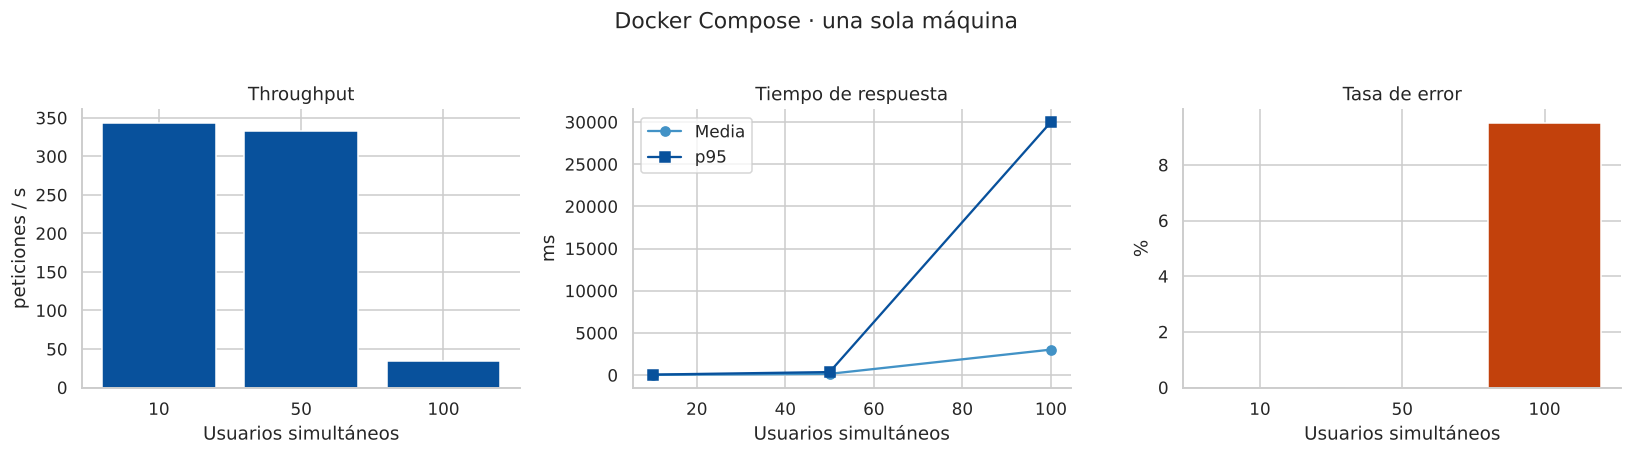

In [8]:
base = resumen[resumen["nodos"] == 0].sort_values("usuarios") if HAY_DATOS else pd.DataFrame()
if base.empty:
    print("Aún no hay mediciones de Docker Compose.")
else:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].bar(base["usuarios"].astype(str), base["throughput_rps"], color=AZULES[3])
    ax[0].set_title("Throughput"); ax[0].set_ylabel("peticiones / s"); ax[0].set_xlabel("Usuarios simultáneos")
    ax[1].plot(base["usuarios"], base["media_ms"], marker="o", color=AZULES[2], label="Media")
    ax[1].plot(base["usuarios"], base["p95_ms"], marker="s", color=AZULES[3], label="p95")
    ax[1].set_title("Tiempo de respuesta"); ax[1].set_ylabel("ms"); ax[1].set_xlabel("Usuarios simultáneos"); ax[1].legend()
    ax[2].bar(base["usuarios"].astype(str), base["error_pct"], color="#c2410c")
    ax[2].set_title("Tasa de error"); ax[2].set_ylabel("%"); ax[2].set_xlabel("Usuarios simultáneos")
    fig.suptitle("Docker Compose · una sola máquina", y=1.03)
    plt.tight_layout(); plt.show()

**Cómo leer estas gráficas.** Con un número fijo de usuarios y sin pausa entre peticiones, el throughput es aproximadamente `usuarios ÷ tiempo de respuesta`. Si al subir de 50 a 100 usuarios el throughput **deja de crecer** y el tiempo de respuesta **sí crece**, el sistema se ha saturado (algún recurso —CPU de la API, base de datos o red— llegó a su límite).

### 7.2 Kubernetes · efecto de las réplicas y de los nodos

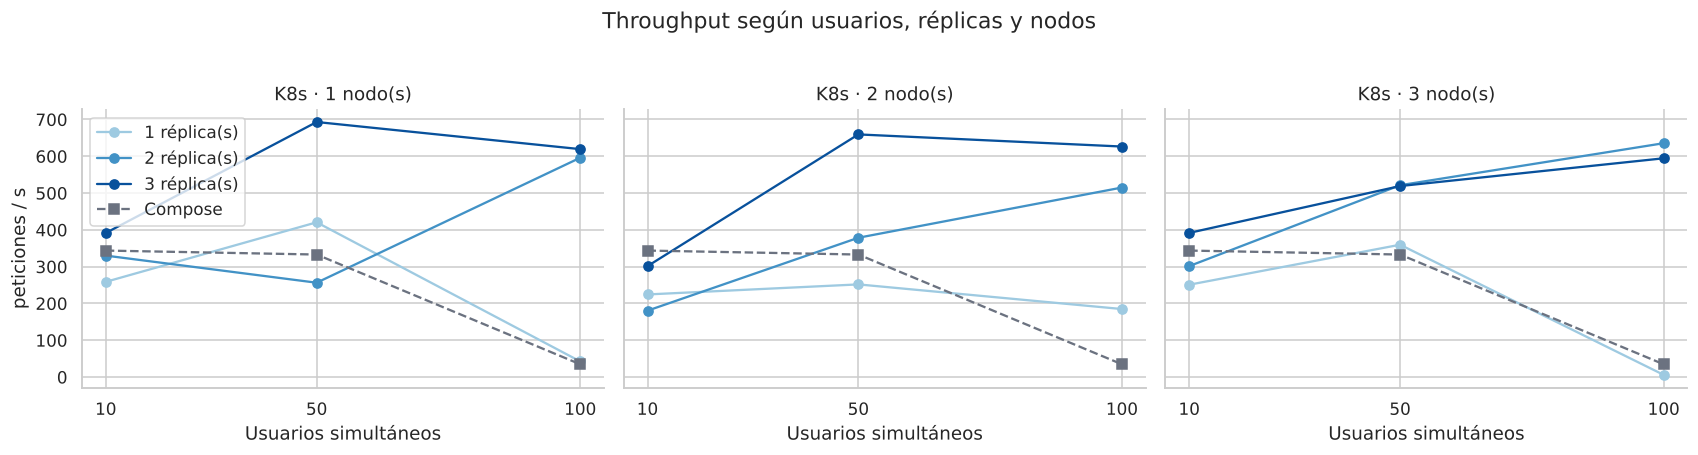

In [9]:
def lineas_por_nodos(metrica, titulo, ylabel):
    if not HAY_DATOS or resumen[resumen["nodos"] > 0].empty:
        print("Aún no hay mediciones de Kubernetes."); return
    nodos_disp = sorted(resumen.loc[resumen["nodos"] > 0, "nodos"].unique())
    base = resumen[resumen["nodos"] == 0].sort_values("usuarios")
    fig, axes = plt.subplots(1, len(nodos_disp), figsize=(5.2 * len(nodos_disp), 4), sharey=True, squeeze=False)
    for ax, nd in zip(axes[0], nodos_disp):
        for r in sorted(resumen[resumen["nodos"] == nd]["replicas"].unique()):
            d = resumen[(resumen["nodos"] == nd) & (resumen["replicas"] == r)].sort_values("usuarios")
            ax.plot(d["usuarios"], d[metrica], marker="o", color=AZULES[r], label=f"{r} réplica(s)")
        if not base.empty:
            ax.plot(base["usuarios"], base[metrica], ls="--", marker="s", color=COLOR_COMPOSE, label="Compose")
        ax.set_title(f"K8s · {nd} nodo(s)"); ax.set_xlabel("Usuarios simultáneos"); ax.set_xticks(NIVELES)
    axes[0][0].set_ylabel(ylabel); axes[0][0].legend()
    fig.suptitle(titulo, y=1.03); plt.tight_layout(); plt.show()

lineas_por_nodos("throughput_rps", "Throughput según usuarios, réplicas y nodos", "peticiones / s")

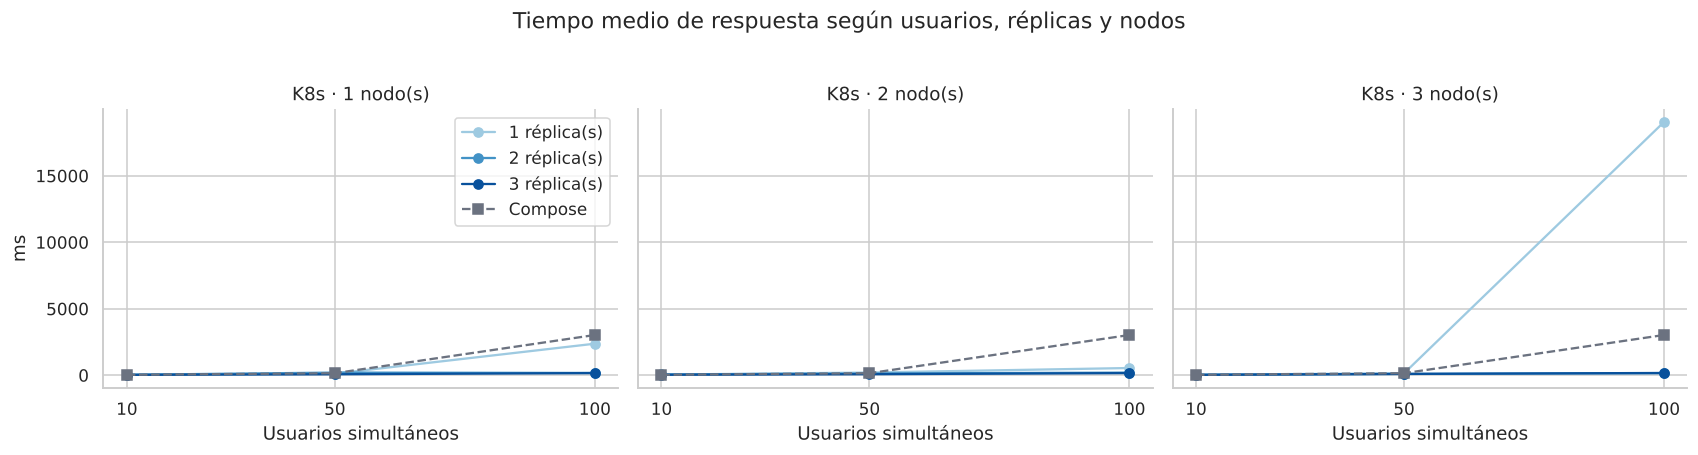

In [10]:
lineas_por_nodos("media_ms", "Tiempo medio de respuesta según usuarios, réplicas y nodos", "ms")

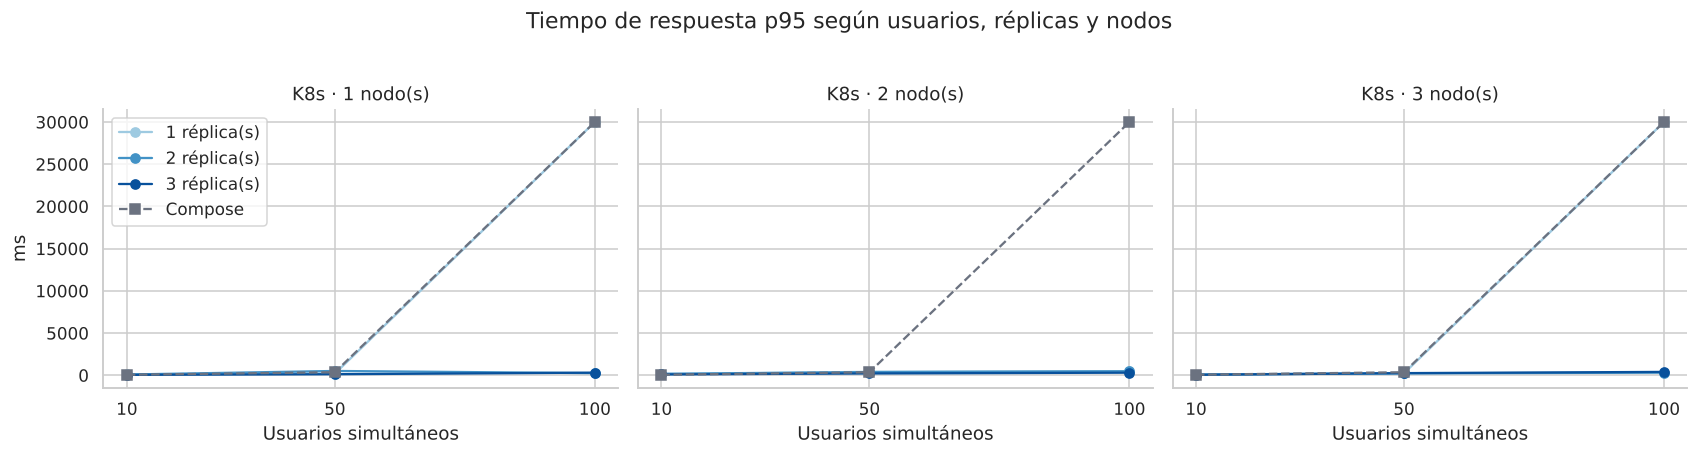

In [11]:
lineas_por_nodos("p95_ms", "Tiempo de respuesta p95 según usuarios, réplicas y nodos", "ms")

### 7.3 Comparación directa a la máxima carga

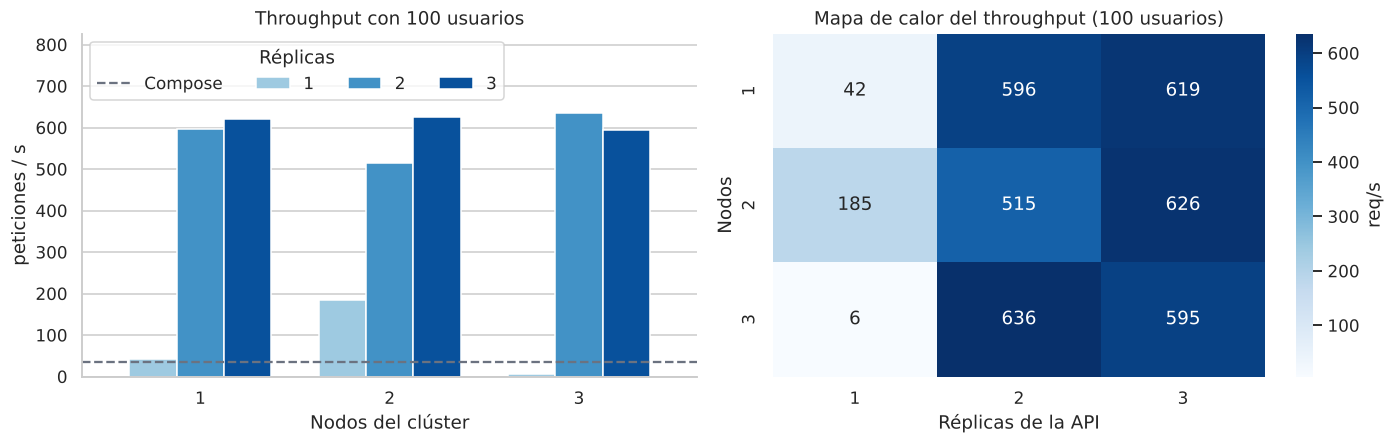

In [12]:
if HAY_DATOS:
    mx = int(resumen["usuarios"].max())
    k = resumen[(resumen["nodos"] > 0) & (resumen["usuarios"] == mx)]
    if k.empty:
        print("Aún no hay mediciones de Kubernetes.")
    else:
        p = k.pivot(index="nodos", columns="replicas", values="throughput_rps")
        fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
        p.plot(kind="bar", ax=ax[0], color=[AZULES[c] for c in p.columns], width=0.75, rot=0)
        b = resumen[(resumen["nodos"] == 0) & (resumen["usuarios"] == mx)]
        if not b.empty:
            ax[0].axhline(b["throughput_rps"].iloc[0], ls="--", color=COLOR_COMPOSE, label="Compose")
        ax[0].set_title(f"Throughput con {mx} usuarios"); ax[0].set_xlabel("Nodos del clúster"); ax[0].set_ylabel("peticiones / s")
        ax[0].set_ylim(0, max(p.values.max(), 1) * 1.3)
        ax[0].grid(axis="x", visible=False)
        ax[0].legend(title="Réplicas", loc="upper left", ncol=4)
        sns.heatmap(p, annot=True, fmt=".0f", cmap="Blues", ax=ax[1], cbar_kws={"label": "req/s"})
        ax[1].set_title(f"Mapa de calor del throughput ({mx} usuarios)"); ax[1].set_xlabel("Réplicas de la API"); ax[1].set_ylabel("Nodos")
        plt.tight_layout(); plt.show()

### 7.4 ¿Qué endpoint es el más lento?

Latencia media por tipo de petición a la máxima carga. Las consultas filtradas y los listados suelen ser más costosos que la lectura por `id`, y las escrituras dependen de la base de datos.

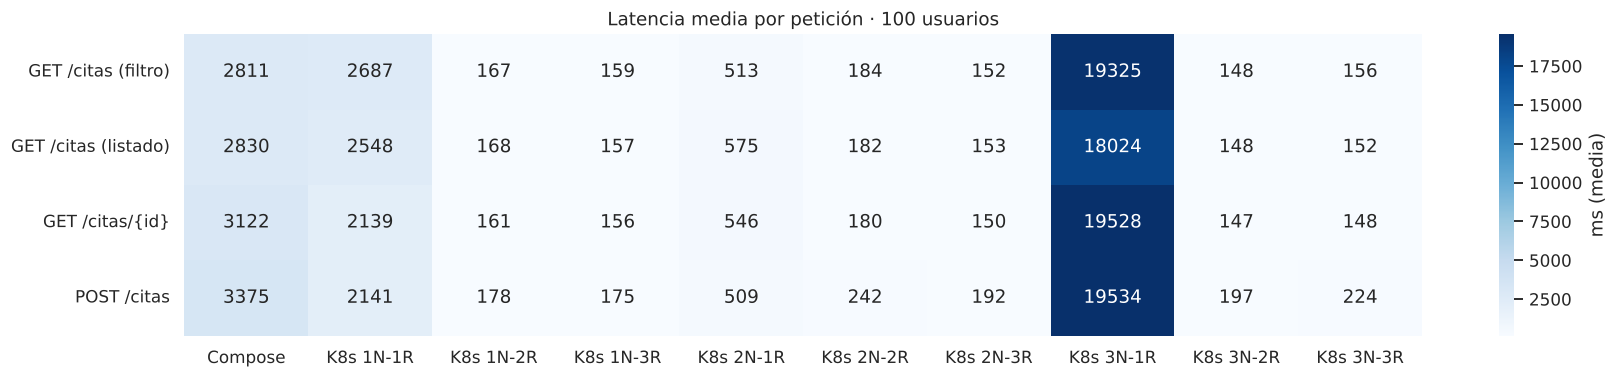

In [13]:
if HAY_DATOS and not por_label.empty:
    mx = int(por_label["usuarios"].max())
    pl = por_label[por_label["usuarios"] == mx].pivot_table(index="label", columns="etiqueta", values="media_ms")
    plt.figure(figsize=(1.3 * max(len(pl.columns), 4) + 3, 3.6))
    sns.heatmap(pl, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "ms (media)"})
    plt.title(f"Latencia media por petición · {mx} usuarios"); plt.xlabel(""); plt.ylabel("")
    plt.tight_layout(); plt.show()
else:
    print("Sin datos todavía.")

### 7.5 Comportamiento en el tiempo (justificación del calentamiento)

Peticiones por segundo y latencia media a lo largo de una prueba. La zona sombreada es la que se **descarta** (rampa + calentamiento).

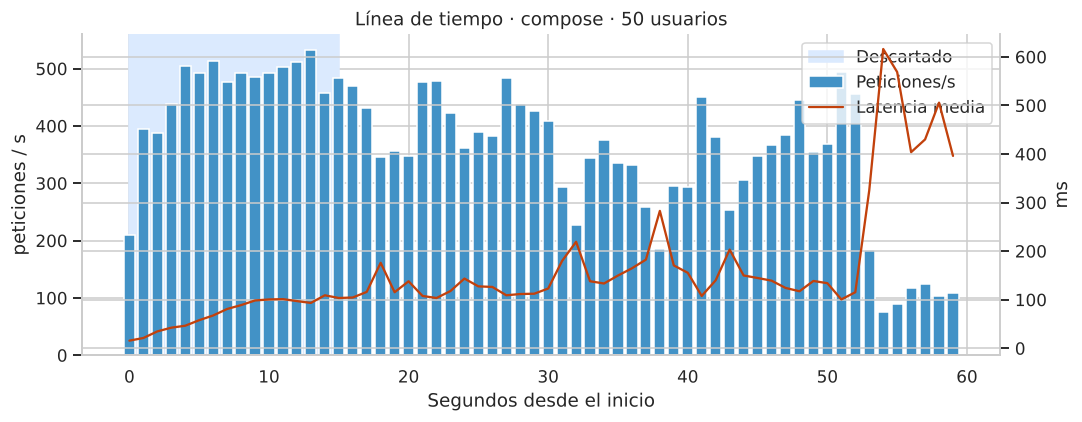

In [14]:
TIMELINE = None    # p. ej. ("compose", 50); por defecto se elige una prueba disponible
if crudos:
    clave = TIMELINE or (("compose", 50) if ("compose", 50) in crudos else sorted(crudos)[0])
    df = crudos[clave]
    seg = df.groupby(df["t"].astype(int)).agg(req=("elapsed", "size"), media=("elapsed", "mean"))
    fig, ax1 = plt.subplots(figsize=(10, 4))
    ax1.axvspan(0, DESCARTE_SEG, color="#dbeafe", label="Descartado")
    ax1.bar(seg.index, seg["req"], color=AZULES[2], label="Peticiones/s")
    ax1.set_xlabel("Segundos desde el inicio"); ax1.set_ylabel("peticiones / s")
    ax2 = ax1.twinx(); ax2.plot(seg.index, seg["media"], color="#c2410c", label="Latencia media")
    ax2.set_ylabel("ms"); ax2.spines["right"].set_visible(True)
    ax1.set_title(f"Línea de tiempo · {clave[0]} · {clave[1]} usuarios")
    h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper right"); plt.tight_layout(); plt.show()
else:
    print("Sin datos todavía.")

### 7.6 Errores

In [15]:
if HAY_DATOS:
    e = resumen[["etiqueta", "usuarios", "n_medido", "error_pct"]].copy()
    e["error_pct"] = e["error_pct"].round(2)
    display(e[e["error_pct"] > 0].rename(columns={"etiqueta": "Escenario", "usuarios": "Usuarios",
                                                  "n_medido": "Peticiones", "error_pct": "Errores (%)"})
            if (e["error_pct"] > 0).any() else "Ninguna prueba registró errores en la ventana medida.")

,Escenario,Usuarios,Peticiones,Errores (%)
2,Compose,100,2101,9.52
5,K8s 1N-1R,100,2740,7.30
14,K8s 2N-1R,100,13783,0.73
23,K8s 3N-1R,100,316,56.96


## 8. Análisis comparativo

Las cifras de esta sección se **calculan a partir de los datos cargados** (así siempre coinciden con las gráficas). La interpretación —el *porqué*— está en la sección 9.

Una advertencia de lectura: las pruebas de **100 usuarios con 1 réplica colapsan** (errores por *timeout*). En ellas el throughput sostenido es muy bajo y muy variable, así que **no se calculan porcentajes de mejora contra esas pruebas**: darían números enormes que no significan nada.

In [16]:
def hallazgos():
    if not HAY_DATOS:
        return ["Todavía no hay mediciones cargadas."]
    out = []
    r = resumen
    mx = int(r["usuarios"].max())

    # 1. Pruebas con colapso
    malos = r[r["error_pct"] > 0.5].sort_values(["usuarios", "etiqueta"])
    if malos.empty:
        out.append("Ninguna prueba superó el 0,5 % de errores.")
    else:
        out.append("Pruebas con colapso (más de 0,5 % de errores): " + "; ".join(
            f"{x.etiqueta} @ {x.usuarios} usuarios ({x.error_pct:.1f} % errores, media {x.media_ms:.0f} ms)" for x in malos.itertuples()) + ".")
        if (malos["usuarios"] < mx).any():
            out.append("Hubo colapsos por debajo de la máxima carga.")
        out.append(f"Todas esas pruebas son de {mx} usuarios y de 1 réplica (o Compose, que también tiene 1 contenedor de API): "
                   + ("se confirma." if (malos["usuarios"] == mx).all() and ((malos["replicas"] <= 1)).all() else "revisar, hay excepciones."))

    # 2. Rendimiento con >= 2 réplicas a la máxima carga
    k2 = r[(r["usuarios"] == mx) & (r["replicas"] >= 2) & (r["error_pct"] <= 0.5)]
    if not k2.empty:
        out.append(f"Con {mx} usuarios y 2 o 3 réplicas (sin errores): throughput entre {k2['throughput_rps'].min():.0f} y "
                   f"{k2['throughput_rps'].max():.0f} req/s, latencia media entre {k2['media_ms'].min():.0f} y {k2['media_ms'].max():.0f} ms "
                   f"({len(k2)} configuraciones).")

    # 3. De 2 a 3 réplicas (solo donde ambas están sin colapso)
    for nd in sorted(r[r["nodos"] > 0]["nodos"].unique()):
        s = r[(r["nodos"] == nd) & (r["usuarios"] == mx)].set_index("replicas")["throughput_rps"]
        if 2 in s.index and 3 in s.index:
            out.append(f"Con {nd} nodo(s) y {mx} usuarios, pasar de 2 a 3 réplicas cambió el throughput en "
                       f"{100 * (s[3] / s[2] - 1):+.0f} % ({s[2]:.0f} → {s[3]:.0f} req/s).")

    # 4. Efecto de los nodos con réplicas fijas
    for rep in (2, 3):
        s = r[(r["replicas"] == rep) & (r["usuarios"] == mx)].set_index("nodos")["throughput_rps"]
        if len(s) > 1:
            out.append(f"Con {rep} réplicas y {mx} usuarios, el throughput en 1/2/3 nodos fue "
                       + " / ".join(f"{s[n]:.0f}" for n in sorted(s.index)) + " req/s.")

    # 5. Variabilidad entre configuraciones equivalentes (1 réplica, pod en el Zorin en las tres)
    eq = r[(r["replicas"] == 1) & (r["nodos"] > 0)]
    for u in (10, 50):
        v = eq[eq["usuarios"] == u]["throughput_rps"]
        if len(v) == 3:
            out.append(f"Variabilidad: las tres pruebas con 1 réplica en el Zorin ({u} usuarios) dieron "
                       + ", ".join(f"{x:.0f}" for x in v) + f" req/s (CV = {100 * v.std() / v.mean():.0f} %).")

    # 6. Compose frente a la configuración equivalente en Kubernetes
    for u in (10, 50):
        c = r[(r["nodos"] == 0) & (r["usuarios"] == u)]
        k = r[(r["escenario"] == "k8s-1n-1r") & (r["usuarios"] == u)]
        if not c.empty and not k.empty:
            out.append(f"Compose frente a K8s 1N-1R con {u} usuarios: {c.iloc[0]['throughput_rps']:.0f} contra {k.iloc[0]['throughput_rps']:.0f} req/s.")
    return out

for linea in hallazgos():
    print("•", linea)


• Pruebas con colapso (más de 0,5 % de errores): Compose @ 100 usuarios (9.5 % errores, media 3023 ms); K8s 1N-1R @ 100 usuarios (7.3 % errores, media 2370 ms); K8s 2N-1R @ 100 usuarios (0.7 % errores, media 541 ms); K8s 3N-1R @ 100 usuarios (57.0 % errores, media 19042 ms).
• Todas esas pruebas son de 100 usuarios y de 1 réplica (o Compose, que también tiene 1 contenedor de API): se confirma.
• Con 100 usuarios y 2 o 3 réplicas (sin errores): throughput entre 515 y 636 req/s, latencia media entre 157 y 194 ms (6 configuraciones).
• Con 1 nodo(s) y 100 usuarios, pasar de 2 a 3 réplicas cambió el throughput en +4 % (596 → 619 req/s).
• Con 2 nodo(s) y 100 usuarios, pasar de 2 a 3 réplicas cambió el throughput en +22 % (515 → 626 req/s).
• Con 3 nodo(s) y 100 usuarios, pasar de 2 a 3 réplicas cambió el throughput en -6 % (636 → 595 req/s).
• Con 2 réplicas y 100 usuarios, el throughput en 1/2/3 nodos fue 596 / 515 / 636 req/s.
• Con 3 réplicas y 100 usuarios, el throughput en 1/2/3 nodos

### Variabilidad entre configuraciones equivalentes

Las configuraciones **1N-1R, 2N-1R y 3N-1R** son, en la práctica, la misma: un solo pod de la API, que el planificador colocó en el portátil Zorin (junto a la base de datos); los nodos extra estaban sin trabajo. Aun así, las tres mediciones difieren. Esa diferencia es una **estimación directa de la variabilidad del experimento** y fija cuánto puede cambiar un resultado sin que haya un efecto real.

In [17]:
if HAY_DATOS:
    eq = resumen[(resumen["replicas"] == 1) & (resumen["nodos"] > 0)]
    t = eq.pivot(index="usuarios", columns="etiqueta", values="throughput_rps")
    t["media"] = t.mean(axis=1)
    t["desv. est."] = t[[c for c in t.columns if c != "media"]].std(axis=1)
    t["CV (%)"] = 100 * t["desv. est."] / t["media"]
    e = eq.pivot(index="usuarios", columns="etiqueta", values="error_pct").add_prefix("errores % ")
    display(pd.concat([t, e], axis=1).round(1))
    print("A 100 usuarios la comparación de throughput no es válida: las tres pruebas colapsan, con proporciones de error muy distintas.")

etiqueta,K8s 1N-1R,K8s 2N-1R,K8s 3N-1R,media,desv. est.,CV (%),errores % K8s 1N-1R,errores % K8s 2N-1R,errores % K8s 3N-1R
usuarios,,,,,,,,,
10,258.8,224.5,250.9,244.7,18.0,7.3,0.0,0.0,0.0
50,420.6,251.8,359.6,344.0,85.5,24.8,0.0,0.0,0.0
100,42.4,184.8,5.9,77.7,94.5,121.7,7.3,0.7,57.0


A 100 usuarios la comparación de throughput no es válida: las tres pruebas colapsan, con proporciones de error muy distintas.


### Uso de CPU observado (monitor)

Durante cada prueba se registró la CPU de los pods (`kubectl top`, en milicores: 1000 m = 1 núcleo) y de los nodos; en Compose, `docker stats` (100 % = 1 núcleo). La tabla muestra el **pico** de cada recurso y sirve para localizar el cuello de botella: un recurso cerca de su límite está saturado; uno lejos, no.

In [18]:
import re

def parsear_monitor(ruta):
    api, db, nodos = [], [], {}
    for linea in open(ruta, encoding="utf-8", errors="ignore"):
        if "%" in linea and "|" not in linea:            # formato docker stats (Compose)
            a = re.search(r"citas-api ([\d.]+)%", linea); d = re.search(r"citas-db ([\d.]+)%", linea)
            if a: api.append(float(a[1]) * 10)           # % de núcleo -> milicores
            if d: db.append(float(d[1]) * 10)
            continue
        api += [float(c) for _, c in re.findall(r"(citas-api-\S+) (\d+)m", linea)]
        db  += [float(c) for _, c in re.findall(r"(citas-db-\S+) (\d+)m", linea)]
        for n, c in re.findall(r"(?:^|; |\| )([a-z0-9-]+) (\d+)m \d+%", linea):
            nodos.setdefault(n, []).append(float(c))
    return api, db, nodos

filas_mon = []
for ruta in sorted(glob.glob(os.path.join(DATOS_DIR, "monitor_*.txt"))):
    esc = os.path.basename(ruta)[len("monitor_"):-4]
    api, db, nodos = parsear_monitor(ruta)
    pico = lambda n: max([max(v) for k, v in nodos.items() if k.startswith(n)] or [np.nan])
    filas_mon.append({"Escenario": esc, "API, pico de un pod (m)": max(api) if api else np.nan,
                      "BD, pico (m)": max(db) if db else np.nan,
                      "Zorin (m)": pico("juanpa"), "agente1 (m)": pico("agente1"), "gp19 (m)": pico("gp19")})
monitor = pd.DataFrame(filas_mon)
if not monitor.empty:
    monitor["_o"] = monitor["Escenario"].map(lambda e: ESCENARIOS.index(e) if e in ESCENARIOS else 99)
    display(monitor.sort_values("_o").drop(columns="_o").round(0).fillna("-").reset_index(drop=True))
else:
    print("No hay archivos de monitor en", DATOS_DIR)

,Escenario,"API, pico de un pod (m)","BD, pico (m)",Zorin (m),agente1 (m),gp19 (m)
0,compose,1435.0,1114.0,-,-,-
1,k8s-1n-1r,1294.0,869.0,2508.0,-,-
2,k8s-1n-2r,1282.0,1649.0,4054.0,-,-
3,k8s-1n-3r,1308.0,2641.0,6864.0,-,-
4,k8s-2n-1r,1198.0,868.0,2534.0,108.0,15.0
5,k8s-2n-2r,1133.0,1022.0,2680.0,727.0,15.0
6,k8s-2n-3r,1323.0,2064.0,5043.0,771.0,15.0
7,k8s-3n-1r,1111.0,876.0,2383.0,99.0,15.0
8,k8s-3n-2r,1322.0,1177.0,2705.0,103.0,876.0
9,k8s-3n-3r,1276.0,1459.0,3178.0,771.0,735.0


## 9. Conclusiones

### 9.1 Condiciones del experimento y limitaciones

Estos puntos condicionan **cómo leer** los resultados:

1. **Una sola repetición por prueba, y la variabilidad es grande.** Las tres configuraciones equivalentes (1 pod en el Zorin) dieron a 50 usuarios 421, 252 y 360 req/s (coeficiente de variación ≈ 25 %); a 10 usuarios, 259, 225 y 251 (≈ 7 %). **Diferencias de ese orden entre escenarios no son concluyentes.**
2. **Nodos heterogéneos.** El Zorin (~18 hilos, 16 GB) es mucho más potente que las VMs (1 CPU, 3,8 GB, compartidas con otras prácticas) y aloja siempre la base de datos y el punto de entrada (NodePort).
3. **Red con latencia variable.** Generador de carga → app y VMs → base de datos viajan por Wi-Fi/red institucional (ping medio ≈ 45 ms, máximo ≈ 117 ms).
4. **Un solo generador de carga** (un portátil con JMeter), que también puede limitar el máximo observable.
5. **El estado de la base crece durante el escenario.** Se reinicia el *seed* antes de cada escenario, pero no entre los niveles de 10, 50 y 100 usuarios; el nivel de 100 se mide siempre sobre la base más grande, tras decenas de miles de `POST`. La línea de tiempo de Compose a 50 usuarios muestra el throughput bajando durante el minuto (de ~500 a ~100 req/s) con la latencia subiendo; no se verificó la causa.
6. **Un solo proceso de API por contenedor** y un pool de 10 + 20 conexiones por réplica.

### 9.2 Conclusiones basadas en los datos

**1. Una réplica no soporta 100 usuarios; con dos sí.** Compose y las tres configuraciones de 1 réplica colapsan a 100 usuarios, con errores de *timeout* de ~30 s (0,7 % a 57 %, según la prueba) y latencias medias de 0,5 a 19 s. Con 2 o 3 réplicas, **ninguna** de las 6 pruebas de 100 usuarios tuvo errores: 515–636 req/s y 157–194 ms de media. Los errores aparecen en bloques de 100 (los 100 usuarios a la vez), lo que indica **bloqueos colectivos** de los hilos esperando una conexión. Es coherente con el agotamiento del pool de SQLAlchemy (30 conexiones por réplica), confirmado en los registros de Compose (`QueuePool limit … timed out`); más réplicas multiplican las conexiones disponibles.

**2. La escalabilidad horizontal es sublineal y se estanca en ~600 req/s.** De 2 a 3 réplicas la mejora a 100 usuarios es pequeña o nula (+4 %, +22 % y −6 % en 1, 2 y 3 nodos: 596 → 619, 515 → 626 y 636 → 595 req/s), es decir, del orden de la variabilidad medida; a 10 usuarios el efecto se pierde en el ruido. A 50 usuarios, 3 réplicas fueron mejores en 1 y 2 nodos (693 y 659 req/s) pero no en 3 (519), dentro de la variabilidad medida. No es posible declarar una aceleración lineal.

**3. Sumar nodos (las VMs) no mejoró el rendimiento.** Con las mismas réplicas, 1, 2 y 3 nodos dieron resultados del mismo orden (2 réplicas: 596 / 515 / 636 req/s; 3 réplicas: 619 / 626 / 595 req/s), sin una tendencia por encima de la variabilidad. Tampoco lo empeoraron de forma visible, pese a que los pods de las VMs consultan la base a través de la red: se esperaba un efecto negativo mayor y no se observó. Coincide con la hipótesis de que las VMs de 1 CPU aportan poco.

**4. Cuello de botella.** El monitor indica que **cada pod de la API satura aproximadamente un núcleo** en el Zorin (picos de 1100–1320 m), y ~600–770 m en las VMs. La base de datos usó hasta 869 m (1 réplica), 1649 m (2) y 2641 m (3) en el Zorin, sin tope configurado. En el estancamiento de ~600 req/s el Zorin usó entre 3 y 7 núcleos de ~18, y las VMs no estaban saturadas. **Ningún recurso monitorizado llegó a su límite en ese punto**, así que el límite no es la CPU de los nodos. Las candidatas, **no verificadas**, son el generador de carga (un portátil con JMeter por Wi-Fi), la red, o la contención interna de PostgreSQL (bloqueos, disco).

**5. Compose frente a Kubernetes.** Con los mismos recursos (1 contenedor de API + 1 base de datos), con 10 y 50 usuarios Compose dio 344 y 333 req/s contra 259 y 421 en K8s 1N-1R: diferencias en ambos sentidos y dentro de la variabilidad. **No se detecta un sobrecoste medible de la orquestación**; la ventaja de Kubernetes está en poder subir réplicas, que es lo que evita el colapso a 100 usuarios.

## 10. Recomendaciones

- **Ajustar el pool o ejecutar varios procesos por contenedor** (p. ej. Gunicorn con workers de uvicorn): una réplica usa un solo núcleo y su pool de 30 conexiones se agota antes que cualquier otro recurso. Sería la primera mejora a probar.
- **Usar PgBouncer** si se escalan las réplicas, para no multiplicar las conexiones directas a PostgreSQL (límite por defecto de 100).
- **Repetir cada prueba al menos 3 veces** y reportar medias con su dispersión; con una sola ejecución no se distingue un efecto real de la variabilidad del entorno.
- **Reiniciar el *seed* entre niveles de carga**, no solo entre escenarios, para que 10, 50 y 100 usuarios se midan sobre la misma base.
- **Probar con un segundo generador de carga** (o desde una máquina cableada) para descartar el generador y la red como límite de los ~600 req/s.
- **Usar nodos homogéneos** y fijar la ubicación de los pods si se quiere medir el efecto de los nodos sin la influencia del planificador.
- Si hay tiempo, desplegar **Prometheus + Grafana** para correlacionar CPU, memoria y conexiones con las métricas de JMeter.

## 11. Cómo reproducir el proyecto

1. **Clonar el repositorio:** `git clone https://github.com/alalo10/Proyecto_kubernetes_k8s.git`
2. **Fase 1 (Compose):** en `docker/`, `docker compose up -d` y cargar los datos con `docker compose exec api python -m scripts.seed`.
3. **Fases 2–4 (Kubernetes):** instalar K3s (control plane en el portátil y VMs como workers) y aplicar los manifiestos de `k8s/`.
4. **Cargar y medir:** desde otra máquina, `.\jmeter\correr_pruebas.ps1 -Escenario <nombre> -HostApi <IP>`. Nombres válidos: `compose`, `k8s-1n-1r` … `k8s-3n-3r`.
5. **Subir resultados:** `git add jmeter/resultados && git commit && git push`.
6. **Analizar:** abrir este notebook en Google Colab y ejecutar *Entorno de ejecución → Ejecutar todo*. Clona el repositorio y lee los `.jtl`.

Las instrucciones detalladas y los enlaces están también en el reporte PDF de la carpeta `report/`.